In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import PartialDependenceDisplay
from sklearn.metrics import (
    roc_auc_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    auc
)
sns.set(style="whitegrid")

***LOAD DATA***

In [2]:
df = pd.read_csv("/content/Loan.csv")
df.head()

,ApplicationDate,Age,AnnualIncome,CreditScore,EmploymentStatus,EducationLevel,Experience,LoanAmount,LoanDuration,MaritalStatus,...,MonthlyIncome,UtilityBillsPaymentHistory,JobTenure,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,LoanApproved,RiskScore
0,2018-01-01,45,39948,617,Employed,Master,22,13152,48,Married,...,3329.000000,0.724972,11,126928,0.199652,0.227590,419.805992,0.181077,0,49.0
1,2018-01-02,38,39709,628,Employed,Associate,15,26045,48,Single,...,3309.083333,0.935132,3,43609,0.207045,0.201077,794.054238,0.389852,0,52.0
2,2018-01-03,47,40724,570,Employed,Bachelor,26,17627,36,Married,...,3393.666667,0.872241,6,5205,0.217627,0.212548,666.406688,0.462157,0,52.0
3,2018-01-04,58,69084,545,Employed,High School,34,37898,96,Single,...,5757.000000,0.896155,5,99452,0.300398,0.300911,1047.506980,0.313098,0,54.0
4,2018-01-05,37,103264,594,Employed,Associate,17,9184,36,Married,...,8605.333333,0.941369,5,227019,0.197184,0.175990,330.179140,0.070210,1,36.0


***DATA CLEANING & VALIDATION***

In [3]:
# Schema
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 36 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ApplicationDate             20000 non-null  object 
 1   Age                         20000 non-null  int64  
 2   AnnualIncome                20000 non-null  int64  
 3   CreditScore                 20000 non-null  int64  
 4   EmploymentStatus            20000 non-null  object 
 5   EducationLevel              20000 non-null  object 
 6   Experience                  20000 non-null  int64  
 7   LoanAmount                  20000 non-null  int64  
 8   LoanDuration                20000 non-null  int64  
 9   MaritalStatus               20000 non-null  object 
 10  NumberOfDependents          20000 non-null  int64  
 11  HomeOwnershipStatus         20000 non-null  object 
 12  MonthlyDebtPayments         20000 non-null  int64  
 13  CreditCardUtilizationRate   200

In [4]:
# Remove duplicates
df = df.drop_duplicates()

In [5]:
# Handle missing values
num_cols = df.select_dtypes(include=["int64", "float64"]).columns
cat_cols = df.select_dtypes(include=["object"]).columns

In [6]:
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
df[cat_cols] = df[cat_cols].fillna(df[cat_cols].mode().iloc[0])

In [8]:
# Range validation
df = df[(df["CreditScore"] >= 300) & (df["CreditScore"] <= 850)]
df = df[df["AnnualIncome"] > 0]
df = df[df["DebtToIncomeRatio"] >= 0]

In [9]:
df.shape

(20000, 36)

***EXPLORATORY DATA ANALYSIS (EDA)***

In [10]:
# Overall approval rate
df["LoanApproved"].mean()

np.float64(0.239)

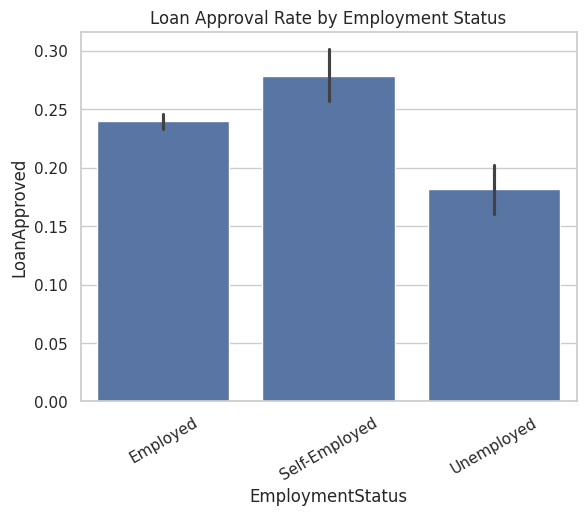

In [11]:
# Approval by Employment Status
plt.figure()
sns.barplot(x="EmploymentStatus", y="LoanApproved", data=df)
plt.title("Loan Approval Rate by Employment Status")
plt.xticks(rotation=30)
plt.show()

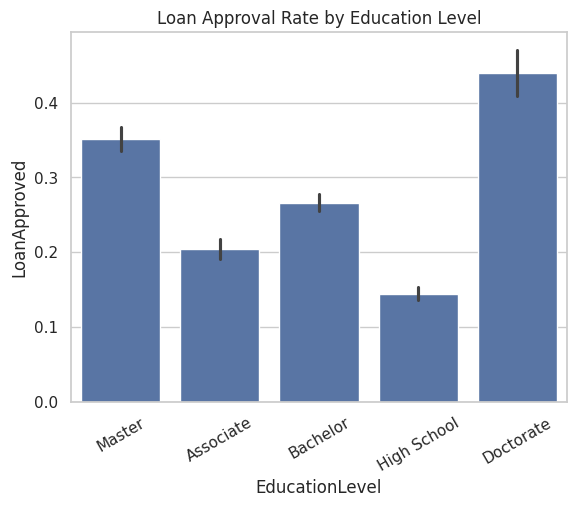

In [12]:
# Approval by Education Level
plt.figure()
sns.barplot(x="EducationLevel", y="LoanApproved", data=df)
plt.title("Loan Approval Rate by Education Level")
plt.xticks(rotation=30)
plt.show()

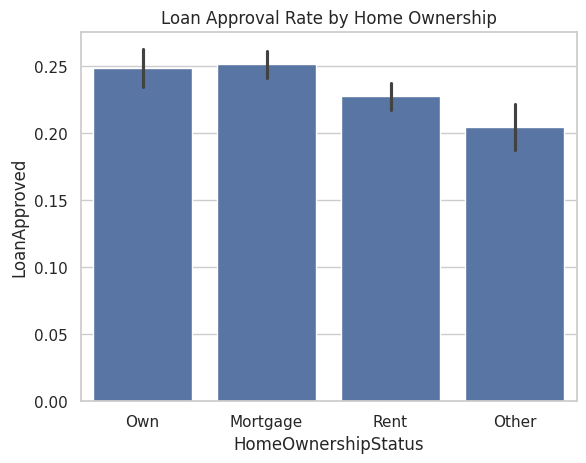

In [14]:
# Approval by Home Ownership
plt.figure()
sns.barplot(x="HomeOwnershipStatus", y="LoanApproved", data=df)
plt.title("Loan Approval Rate by Home Ownership")
plt.show()

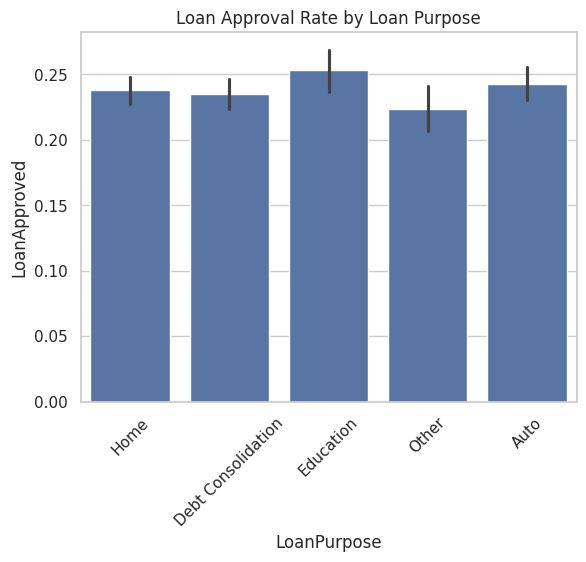

In [15]:
# Approval by Loan Purpose
plt.figure()
sns.barplot(x="LoanPurpose", y="LoanApproved", data=df)
plt.title("Loan Approval Rate by Loan Purpose")
plt.xticks(rotation=45)
plt.show()

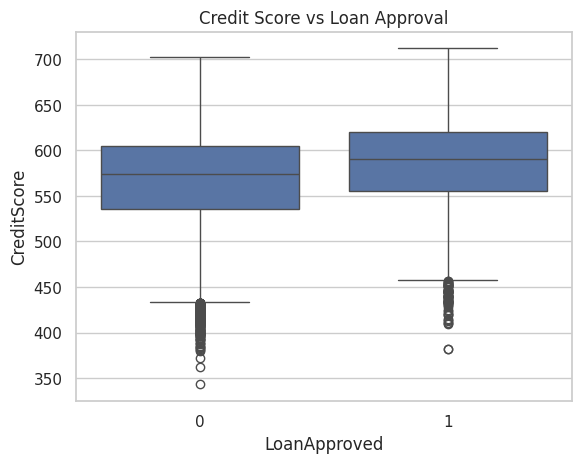

In [16]:
# Credit Score vs Approval
plt.figure()
sns.boxplot(x="LoanApproved", y="CreditScore", data=df)
plt.title("Credit Score vs Loan Approval")
plt.show()

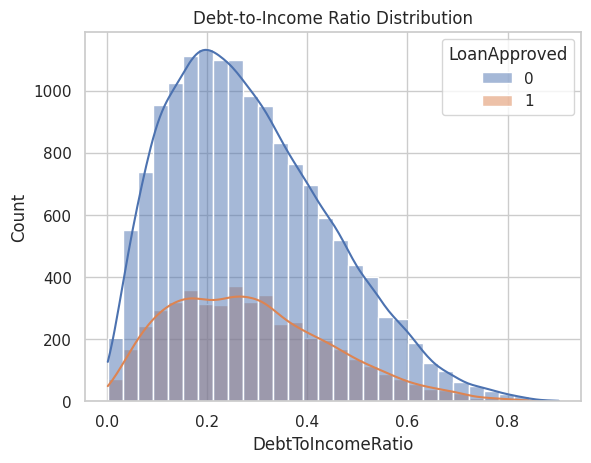

In [17]:
# Debt-to-Income Ratio
plt.figure()
sns.histplot(data=df, x="DebtToIncomeRatio", hue="LoanApproved", bins=30, kde=True)
plt.title("Debt-to-Income Ratio Distribution")
plt.show()

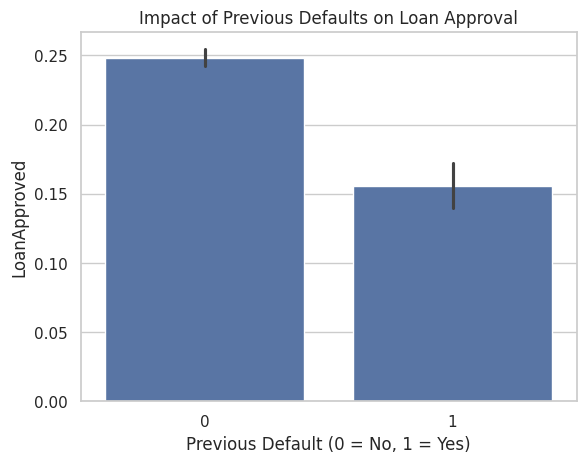

In [19]:
# Impact of Previous Defaults
plt.figure()
sns.barplot(x="PreviousLoanDefaults", y="LoanApproved", data=df)
plt.title("Impact of Previous Defaults on Loan Approval")
plt.xlabel("Previous Default (0 = No, 1 = Yes)")
plt.show()

***HIGH-RISK SEGMENT IDENTIFICATION***

In [21]:
high_risk = df[
    (df["CreditScore"] < 600) &
    (df["DebtToIncomeRatio"] > 0.4) &
    (df["PreviousLoanDefaults"] == 1)
]

high_risk["LoanApproved"].mean()

np.float64(0.1196319018404908)

***FEATURE ENGINEERING***

In [32]:
X = df.drop(["LoanApproved", "ApplicationDate"], axis=1)
y = df["LoanApproved"]

In [33]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X.select_dtypes(include=["object"]).columns

In [40]:
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

***TRAIN / TEST SPLIT***

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

***MODELING***

In [42]:
# ---- KNN ----
knn_pipeline = Pipeline([
    ("prep", preprocessor),
    ("model", KNeighborsClassifier())
])

In [44]:
knn_params = {"model__n_neighbors": [3, 5, 7, 9]}
knn_grid = GridSearchCV(knn_pipeline, knn_params, cv=5, scoring="roc_auc")
knn_grid.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('prep',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         Index(['Age', 'AnnualIncome', 'CreditScore', 'Experience', 'LoanAmount',
       'LoanDuration', 'NumberOfDependents', 'MonthlyDebtPayments',
       'CreditCardUtilizationRate', 'NumberOfOpenCreditLines',
       'NumberOfCreditInquiries', 'DebtToIncomeRatio', 'BankruptcyHisto...
       'JobTenure', 'NetWorth', 'BaseInterestRate', 'InterestRate',
       'MonthlyLoanPayment', 'TotalDebtToIncomeRatio', 'RiskScore'],
      dtype='object')),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         Index(['EmploymentStatus', 'EducationLevel', 'MaritalStatus',
       'HomeOwnershipStatus', 'LoanPurpose'],
      dtype='object'))])),
                                       ('model', KNeighborsClassifier())]),
             param_grid={'model__n_neighbors': [3, 5, 7, 9]},
             scoring='roc_auc')

In [45]:
# ---- Decision Tree ----
dt_pipeline = Pipeline([
    ("prep", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])

In [46]:
dt_params = {
    "model__max_depth": [3, 5, 7, None],
    "model__min_samples_split": [2, 10, 20]
}

In [47]:
dt_grid = GridSearchCV(dt_pipeline, dt_params, cv=5, scoring="roc_auc")
dt_grid.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('prep',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         Index(['Age', 'AnnualIncome', 'CreditScore', 'Experience', 'LoanAmount',
       'LoanDuration', 'NumberOfDependents', 'MonthlyDebtPayments',
       'CreditCardUtilizationRate', 'NumberOfOpenCreditLines',
       'NumberOfCreditInquiries', 'DebtToIncomeRatio', 'BankruptcyHisto...
       'MonthlyLoanPayment', 'TotalDebtToIncomeRatio', 'RiskScore'],
      dtype='object')),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         Index(['EmploymentStatus', 'EducationLevel', 'MaritalStatus',
       'HomeOwnershipStatus', 'LoanPurpose'],
      dtype='object'))])),
                                       ('model',
                                        DecisionTreeClassifier(random_state=42))]),
             param_grid={'model__max_depth': [3, 5, 7, None],
                         'model__min_samples_split': [2, 10, 20]},
             scoring='roc_auc')

In [48]:
# ---- Random Forest ----
rf_pipeline = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

In [49]:
rf_params = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 10, None]
}

In [50]:
rf_grid = GridSearchCV(rf_pipeline, rf_params, cv=5, scoring="roc_auc")
rf_grid.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('prep',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         Index(['Age', 'AnnualIncome', 'CreditScore', 'Experience', 'LoanAmount',
       'LoanDuration', 'NumberOfDependents', 'MonthlyDebtPayments',
       'CreditCardUtilizationRate', 'NumberOfOpenCreditLines',
       'NumberOfCreditInquiries', 'DebtToIncomeRatio', 'BankruptcyHisto...
       'MonthlyLoanPayment', 'TotalDebtToIncomeRatio', 'RiskScore'],
      dtype='object')),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         Index(['EmploymentStatus', 'EducationLevel', 'MaritalStatus',
       'HomeOwnershipStatus', 'LoanPurpose'],
      dtype='object'))])),
                                       ('model',
                                        RandomForestClassifier(random_state=42))]),
             param_grid={'model__max_depth': [5, 10, None],
                         'model__n_estimators': [100, 200]},
             scoring='roc_auc')

***MODEL COMPARISON (ROC-AUC & PR-AUC)***

In [51]:
models = {
    "KNN": knn_grid,
    "Decision Tree": dt_grid,
    "Random Forest": rf_grid
}
results = []

In [52]:
for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    roc = roc_auc_score(y_test, y_prob)

    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    pr_auc = auc(recall, precision)

    results.append([name, roc, pr_auc])


In [53]:
results_df = pd.DataFrame(results, columns=["Model", "ROC-AUC", "PR-AUC"])
results_df

,Model,ROC-AUC,PR-AUC
0,KNN,0.992508,0.982421
1,Decision Tree,0.993049,0.989249
2,Random Forest,0.999214,0.997558


***CONFUSION MATRIX & CLASSIFICATION REPORT – ALL MODELS***

In [54]:
for name, model in models.items():
    print("\n" + "="*40)
    print(f"MODEL: {name}")
    print("="*40)

    y_pred = model.predict(X_test)

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))



MODEL: KNN
Confusion Matrix:
[[3778   27]
 [ 160 1035]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.99      0.98      3805
           1       0.97      0.87      0.92      1195

    accuracy                           0.96      5000
   macro avg       0.97      0.93      0.95      5000
weighted avg       0.96      0.96      0.96      5000


MODEL: Decision Tree
Confusion Matrix:
[[3787   18]
 [  43 1152]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      3805
           1       0.98      0.96      0.97      1195

    accuracy                           0.99      5000
   macro avg       0.99      0.98      0.98      5000
weighted avg       0.99      0.99      0.99      5000


MODEL: Random Forest
Confusion Matrix:
[[3787   18]
 [  36 1159]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99     

***MODEL INTERPRETABILITY (BEST MODEL)***

In [55]:
best_model = rf_grid.best_estimator_

rf_model = best_model.named_steps["model"]
feature_names = numeric_features.tolist() + categorical_features.tolist()

In [58]:
feature_names_out = best_model.named_steps['prep'].get_feature_names_out()
importances = pd.Series(
    rf_model.feature_importances_,
    index=feature_names_out
).sort_values(ascending=False)

importances.head(10)

,0
num__RiskScore,0.444840
num__TotalDebtToIncomeRatio,0.126353
num__MonthlyIncome,0.100766
num__AnnualIncome,0.098230
num__InterestRate,0.038692
num__LoanAmount,0.022664
num__BaseInterestRate,0.016877
num__NetWorth,0.016815
num__TotalAssets,0.014984
num__MonthlyLoanPayment,0.013713


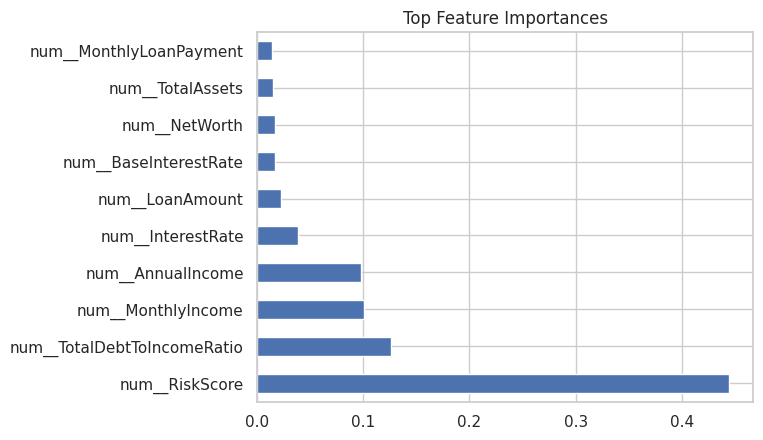

In [59]:
# Feature Importance Plot
importances.head(10).plot(kind="barh")
plt.title("Top Feature Importances")
plt.show()

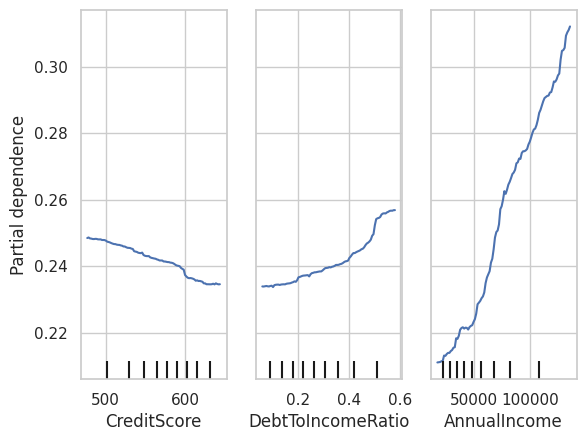

In [61]:
# Partial Dependence Plots
PartialDependenceDisplay.from_estimator(
    best_model,
    X_train,
    features=["CreditScore", "DebtToIncomeRatio", "AnnualIncome"]
)
plt.show()